<div style="background-color:#000;"><img src="pqn.png"></img></div><div><a href="https://pyquantnews.com/">PyQuant News</a> is where finance practitioners level up with Python for quant finance, algorithmic trading, and market data analysis. Looking to get started? Check out the fastest growing, top-selling course to <a href="https://www.pyquantnews.com/getting-started-with-python-for-quant-finance/">get started with Python for quant finance</a>. For educational purposes. Not investment advice. Use at your own risk.</div>

## Install the libraries

Install OpenBB to download option quotes, pysabr to fit the volatility curve, and matplotlib to draw the charts. The `routers` extra adds OpenBB's options commands, and `openbb-yfinance` adds Yahoo Finance as a data source.

In [ ]:
!pip install "openbb[routers]" openbb-yfinance pysabr matplotlib numpy pandas

Restart the kernel after the install finishes so Python loads the new packages.

## Import the libraries

pandas holds the option chain in a table and numpy handles the math. OpenBB downloads the SPY quotes. From pysabr we import three things: a class that fits the SABR curve, a module with the formula that reads a volatility off that curve, and Black's formula, which turns a volatility into an option price.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from openbb import obb
from pysabr import Hagan2002LognormalSABR
from pysabr import hagan_2002_lognormal_sabr as sabr
from pysabr.black import lognormal_call

## Download the SPY option chain

Set the ticker, the expiration to study, and the interest rate. The rate is an input you choose, so update it to the current 3-month Treasury bill yield before you run the notebook.

In [2]:
symbol = "SPY"
expiration = pd.Timestamp("2027-01-15")
rate = 0.04

Download every SPY call and put that Yahoo Finance lists today. Name the provider, because OpenBB tries other data sources first when you leave it out, and those return different columns.

In [3]:
spy = obb.derivatives.options.chains(symbol, provider="yfinance").to_dataframe()

## Pick one monthly expiration

SPY lists options that expire on every trading day. The standard monthly options expire on the third Friday of the month, which always falls between the 15th and the 21st. Monthly options usually have more open interest than the daily and weekly options around them, so their quotes are more reliable.

OpenBB returns expiration dates as plain Python dates. Convert them to pandas dates first so we can ask for the weekday and the day of the month.

In [4]:
spy["expiration"] = pd.to_datetime(spy["expiration"])

# pandas counts days of the week from Monday = 0, so Friday is 4
exp = spy["expiration"].dt
monthly = spy[(exp.day_of_week == 4) & exp.day.between(15, 21)]
monthly["expiration"].unique()

<DatetimeArray>
['2026-11-20 00:00:00', '2026-12-18 00:00:00', '2027-01-15 00:00:00',
 '2027-02-19 00:00:00', '2027-03-19 00:00:00', '2027-04-16 00:00:00',
 '2027-09-17 00:00:00', '2027-12-17 00:00:00', '2028-01-21 00:00:00',
 '2028-06-16 00:00:00', '2028-12-15 00:00:00', '2029-01-19 00:00:00']
Length: 12, dtype: datetime64[ns]

Check that 2027-01-15 is in the list. Then keep only that expiration and drop contracts with no bid. A zero bid means no one wants to buy, so the price tells us nothing. The mid price sits halfway between the bid and the ask.

In [5]:
chain = monthly[(monthly["expiration"] == expiration) & (monthly["bid"] > 0)].copy()
chain["mid"] = (chain["bid"] + chain["ask"]) / 2

## Estimate the forward price

SABR works with the forward price: the price for SPY on the expiration date that the option market implies today. Put-call parity gives it to us. At any strike, the call price minus the put price equals the gap between the forward and the strike. We use the strike where the call and put prices are closest, because quotes near the money are the most active. This forward already includes SPY's dividends, so we never have to guess a dividend yield.

In [6]:
# Time to expiration in years
t = (expiration - pd.Timestamp.now()).days / 365

calls = chain[chain["option_type"] == "call"].set_index("strike")["mid"]
puts = chain[chain["option_type"] == "put"].set_index("strike")["mid"]
call_minus_put = (calls - puts).dropna()

atm_strike = call_minus_put.abs().idxmin()
f = atm_strike + np.exp(rate * t) * call_minus_put[atm_strike]

spot = chain["underlying_price"].iloc[0]
print("Spot:", spot)
print("Forward:", round(f, 2))
print("Years to expiration:", round(t, 3))

Spot: 749.6
Forward: 755.85
Years to expiration: 0.167


The forward should land close to spot. If it lands far away, the call or put quote at that strike is probably stale.

## Keep clean out-of-the-money quotes

Deep in-the-money options trade rarely and have wide spreads, so their implied volatilities are noisy. We keep puts below the forward and calls above it. These out-of-the-money options cover every strike and trade the most. We also drop wide markets, strikes with no open contracts, and implied volatilities that look broken.

In [7]:
chain["spread_pct"] = (chain["ask"] - chain["bid"]) / chain["mid"]

out_of_the_money = (
    ((chain["option_type"] == "put") & (chain["strike"] < f))
    | ((chain["option_type"] == "call") & (chain["strike"] >= f))
)

smile = chain[
    out_of_the_money
    & (chain["spread_pct"] < 0.25)  # spread under 25% of the mid
    & (chain["open_interest"] > 0)  # someone holds the contract
    & chain["implied_volatility"].between(0.01, 2)  # between 1% and 200%
]
smile = smile.set_index("strike").sort_index()

Pull out the strikes and convert implied volatility from decimals to percent, the unit pysabr's fit expects.

In [8]:
strikes = smile.index
vols = smile["implied_volatility"] * 100

SPY's implied volatility is not flat across strikes. Low strikes carry higher volatility than high strikes because investors pay extra for crash protection. SABR fits a smooth curve through that slope.

## Fit the SABR curve

SABR describes the curve with four numbers: alpha, beta, rho, and volvol. Beta and rho both tilt the curve, so the fit can't tell them apart well. The usual approach is to pick beta yourself and let the fit solve for the other three. We use 0.5. Try 0.3 or 1.0 and you will see the fitted curve barely move. Alpha changes a lot, because its scale depends on beta.

In [9]:
beta = 0.5

sabr_lognormal = Hagan2002LognormalSABR(f=f, t=t, beta=beta)
alpha, rho, volvol = sabr_lognormal.fit(strikes, vols)

print("alpha:", round(alpha, 4))
print("rho:", round(rho, 4))
print("volvol:", round(volvol, 4))

alpha: 4.0145
rho: -0.6544
volvol: 2.1907


Alpha sets the height of the curve. Rho sets the tilt, and a negative rho means low strikes carry higher volatility. Volvol, called nu in Hagan's paper, sets how much the curve bends. Hagan's 2002 formula turns these four numbers into a volatility at any strike with plain arithmetic, so there is no simulation to run.

Read the fitted volatility at each strike.

In [10]:
calibrated_vols = [
    sabr.lognormal_vol(strike, f, t, alpha, beta, rho, volvol) * 100
    for strike in strikes
]
calibrated_vols = pd.Series(calibrated_vols, index=strikes)

The formula works at any strike, including strikes with no quote today. That is how a fitted curve fills the gaps in a strike grid.

Plot the fitted curve over the market quotes.

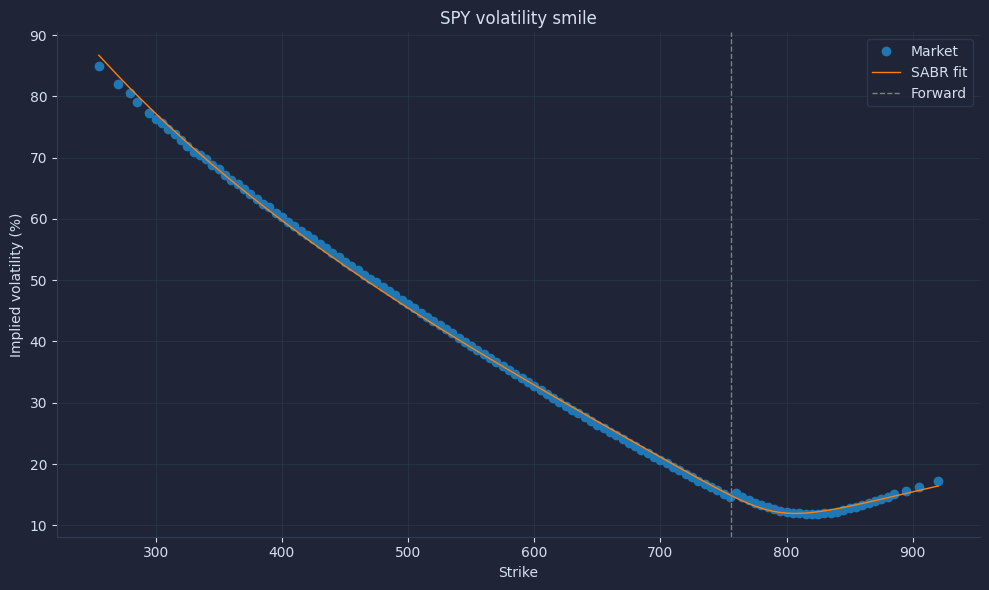

In [11]:
plt.plot(strikes, vols, "o", label="Market")
plt.plot(strikes, calibrated_vols, label="SABR fit")
plt.axvline(f, color="gray", linestyle="--", label="Forward")
plt.xlabel("Strike")
plt.ylabel("Implied volatility (%)")
plt.title("SPY volatility smile")
plt.legend()
plt.show()

The fitted line should run through the middle of the quotes. List the strikes where the fit misses by the most.

In [12]:
fit_error = (vols - calibrated_vols).abs()
fit_error.sort_values(ascending=False).head(10)

strike
255.0    1.737680
270.0    1.353171
285.0    1.123685
295.0    0.853565
300.0    0.838022
920.0    0.810183
280.0    0.793365
475.0    0.791097
760.0    0.770611
490.0    0.727833
dtype: float64

Before you blame the model for a big miss, check that strike's volume and bid-ask spread. The fit gives every strike the same weight, so one stale quote can pull the curve toward it.

## Compare model prices to market prices

Black's formula turns each fitted volatility back into a dollar price. We price puts below the forward and calls above it, to match the quotes we kept. pysabr names the function `lognormal_call`, but it prices puts too when you pass `cp="put"`. Black's formula starts from the forward, which already includes dividends, so the rate only discounts the price back to today.

In [13]:
model_prices = []
for strike, vol, option_type in zip(strikes, calibrated_vols, smile["option_type"]):
    price = lognormal_call(strike, f, t, vol / 100, rate, cp=option_type)
    model_prices.append(price)

Put the model prices next to the market quotes.

In [14]:
prices = pd.DataFrame(
    {
        "bid": smile["bid"],
        "ask": smile["ask"],
        "market": smile["mid"],
        "model": model_prices,
    },
    index=strikes,
)
prices["gap"] = prices["model"] - prices["market"]

Chart the dollar gap between the model price and the market mid at each strike.

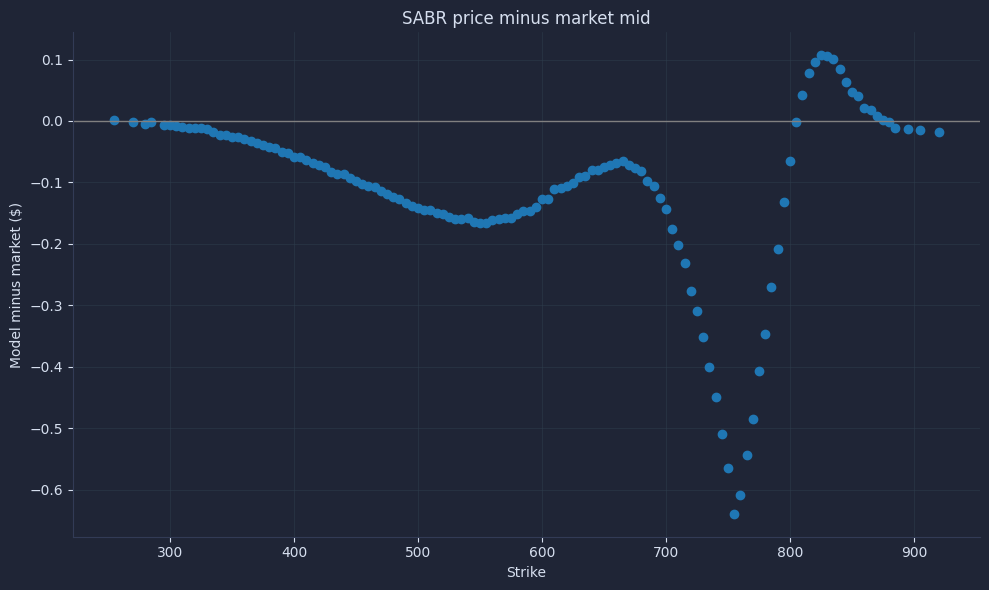

In [15]:
plt.plot(prices.index, prices["gap"], "o")
plt.axhline(0, color="gray")
plt.xlabel("Strike")
plt.ylabel("Model minus market ($)")
plt.title("SABR price minus market mid")
plt.show()

A gap is not a trade. Dollar gaps are usually biggest near the money, because a small volatility miss moves an at-the-money price the most. Yahoo also computes its implied volatilities with its own assumptions, which adds small gaps of its own.

A better test is whether the model price lands inside the bid-ask spread. SPY spreads are tight, so expect a three-parameter curve to miss many of them.

In [16]:
outside = (prices["model"] < prices["bid"]) | (prices["model"] > prices["ask"])
print("Strikes outside the spread:", outside.sum(), "of", len(prices))
prices[outside]

Strikes outside the spread: 117 of 126


,bid,ask,market,model,gap
strike,,,,,
280.0,0.06,0.07,0.065,0.059542,-0.005458
295.0,0.07,0.08,0.075,0.069178,-0.005822
305.0,0.08,0.09,0.085,0.076371,-0.008629
315.0,0.09,0.10,0.095,0.084252,-0.010748
320.0,0.09,0.11,0.100,0.088473,-0.011527
...,...,...,...,...,...
865.0,0.10,0.12,0.110,0.127074,0.017074
885.0,0.07,0.09,0.080,0.068078,-0.011922
895.0,0.06,0.07,0.065,0.051443,-0.013557


Start with the biggest gaps. Check each strike's volume, open interest, and last trade time before you trust the quote.

<a href="https://pyquantnews.com/">PyQuant News</a> is where finance practitioners level up with Python for quant finance, algorithmic trading, and market data analysis. Looking to get started? Check out the fastest growing, top-selling course to <a href="https://www.pyquantnews.com/getting-started-with-python-for-quant-finance/">get started with Python for quant finance</a>. For educational purposes. Not investment advice. Use at your own risk.